# 02 · Estudiantes: modelado

Proyecto del curso Machine Learning (650064), Universidad de Lima, ciclo 2026-2.  
**Objetivo del notebook:** entrenar y comparar los modelos de referencia y los métodos nuevos (KNN y MLP) en los dos escenarios; el escenario principal es E1 (al matricularse).  
**Decisiones:** `documentacion/diseno_experimental.md` (las secciones del diseño se citan como §).

## Autores por sección

| Sección | Autor |
|---|---|
| Todas las secciones de este notebook | Eduardo Gabriel Tello Yparraguirre |
| Funciones de `utilidades.py` | Marcelo David Jesus Cueto Vassallo |

## 0. Configuración

**Qué hacemos:** preparamos el entorno y cargamos las librerías.

**Por qué:** la celda 0 hace que el mismo notebook funcione en VS Code y en Colab, con las versiones fijadas en `requirements.txt`.

In [1]:
# Celda 0. Configuración del entorno: funciona igual en VS Code y en Colab.
import os
import sys

EN_COLAB = "google.colab" in sys.modules
USUARIO_GITHUB = "MCuetoV"
REPOSITORIO = "proyecto-ml-2026-2"

if EN_COLAB:
    # En Colab: clonar el repositorio (o actualizarlo) con el token guardado en Secrets
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    if not os.path.exists(f"/content/{REPOSITORIO}"):
        !git clone -q https://{token}@github.com/{USUARIO_GITHUB}/{REPOSITORIO}.git /content/{REPOSITORIO}
    os.chdir(f"/content/{REPOSITORIO}")
    !git pull -q
    !pip install -q -r requirements.txt
else:
    # En VS Code: si el notebook se abrió desde notebooks/, subir a la raíz del repositorio
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /Users/marce/Documents/CURSOS_UNIVERSIDAD/MachineLearning/proyecto-ml-2026-2


In [2]:
# Librerías y funciones comunes del proyecto
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import utilidades

pd.set_option("display.max_columns", 50)
print("Semilla del proyecto:", utilidades.SEMILLA)

Semilla del proyecto: 42


In [3]:
# Librerías del modelado
import time
import warnings
import numpy as np
import optuna
from optuna.samplers import TPESampler
from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline   # admite pasos de remuestreo dentro del Pipeline

optuna.logging.set_verbosity(optuna.logging.WARNING)   # sin un mensaje por cada trial

/Users/marce/Documents/CURSOS_UNIVERSIDAD/MachineLearning/proyecto-ml-2026-2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga, escenarios y partición

**Qué hacemos:** cargamos los datos, recuperamos la partición del notebook de exploración y definimos las variables de cada escenario y las particiones de la validación cruzada.

**Por qué:** todos los modelos se comparan con las mismas filas, las mismas variables y los mismos *folds* (diseño, §7). El target se codifica como enteros porque `MLPClassifier` de scikit-learn 1.6.1 falla con *early stopping* y clases de texto.

In [4]:
# Datos, partición única (§7), escenarios (§1) y validación cruzada de 5 folds
SEMILLA = utilidades.SEMILLA
datos = utilidades.cargar_estudiantes()
train, test = utilidades.dividir_train_test(datos, "estudiantes")
y_train = utilidades.codificar_objetivo(train[utilidades.OBJETIVO_ESTUDIANTES], "estudiantes")
y_test = utilidades.codificar_objetivo(test[utilidades.OBJETIVO_ESTUDIANTES], "estudiantes")
CLASES = utilidades.CLASES_ESTUDIANTES
ETIQUETAS = ["Abandono", "Matriculado", "Graduado"]   # nombres en español para las figuras
GRUPOS = None                      # estudiantes: CV estratificada simple
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # mismos folds que evaluar_cv
ESCENARIOS = {esc: utilidades.columnas_por_escenario("estudiantes", esc) for esc in ["E1", "E2"]}
PRINCIPAL = "E1"
print("Train:", len(train), "· Test:", len(test), "·", {e: len(v) for e, v in ESCENARIOS.items()})
filas_resultados = []   # registro de resultados de este notebook (§11.2)

Train: 3539 · Test: 885 · {'E1': 24, 'E2': 36}


## 2. Pipeline de preprocesamiento

**Qué hacemos:** definimos una función que arma el `Pipeline` de cada modelo y revisamos cuántas columnas produce la codificación.

**Por qué:** la codificación, el escalado, el remuestreo y la selección van dentro del `Pipeline`, así que en la CV se aprenden en cada fold y nunca ven la validación ni el test (diseño, §4.2, §5 y §6).

In [5]:
# Pipeline: [SMOTENC] → codificación y escalado → [selector L1] → modelo
CATEGORICAS = utilidades.NOMINALES_ESTUDIANTES + utilidades.BINARIAS_ESTUDIANTES   # para SMOTENC

def crear_pipeline(modelo, escenario, balanceo=False, seleccion=False):
    pasos = []
    if balanceo:
        pasos.append(("balanceo", SMOTENC(categorical_features=CATEGORICAS, random_state=SEMILLA)))
    pasos.append(("preprocesamiento", utilidades.crear_preprocesador("estudiantes", escenario)))
    if seleccion:
        lasso = LogisticRegression(penalty="l1", solver="saga", C=1.0, max_iter=5000)
        pasos.append(("seleccion", SelectFromModel(lasso)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

In [6]:
# Columnas que produce la codificación en cada escenario (ajustada solo con el train)
for escenario, columnas in ESCENARIOS.items():
    matriz = utilidades.crear_preprocesador("estudiantes", escenario).fit_transform(train[columnas])
    print(escenario, "→", len(columnas), "variables originales →", matriz.shape[1], "columnas")

E1 → 24 variables originales → 94 columnas
E2 → 36 variables originales → 106 columnas


**Qué observamos:** la codificación produce 94 columnas en E1 y 106 en E2, aunque los niveles con menos del 1% se agrupan. Casi todas vienen del *one-hot* de las 9 nominales; esa alta dimensión es un reto para KNN, que mide distancias en todas las columnas a la vez.

## 3. Modelos de referencia

**Qué hacemos:** entrenamos el piso trivial y el método de los autores en cada escenario.

**Por qué:** el Dummy es el piso: cualquier modelo útil debe superarlo. El Random Forest con sobremuestreo es el método de referencia de los propios autores (Martins et al., 2021; Martins et al., 2023); lo reproducimos en nuestras mismas condiciones y con `GridSearchCV`, la búsqueda que usaron ellos y que vimos en clase (diseño, §2.2).

In [7]:
# Piso: el Dummy siempre predice la clase más frecuente del train
MODELOS_FINALES = {}   # (modelo, escenario) → Pipeline sin entrenar; se evalúan en §8 y §9
HIPERPARAMETROS = []   # filas de la tabla 2
for escenario in ESCENARIOS:
    MODELOS_FINALES[("Dummy", escenario)] = crear_pipeline(DummyClassifier(strategy="most_frequent"), escenario)

In [8]:
# Referencia de los autores: Random Forest con SMOTENC, ajustado con GridSearchCV
MALLA_RF = {"modelo__n_estimators": [200, 500], "modelo__max_depth": [None, 10, 20],
            "modelo__max_features": ["sqrt", 0.5]}
PARAMETROS_RF = {}
for escenario, columnas in ESCENARIOS.items():
    rf = crear_pipeline(RandomForestClassifier(random_state=SEMILLA), escenario, balanceo=True)
    busqueda = GridSearchCV(rf, MALLA_RF, cv=CV, scoring="f1_macro", n_jobs=-1).fit(train[columnas], y_train)
    PARAMETROS_RF[escenario] = {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()}
    modelo = RandomForestClassifier(random_state=SEMILLA, **PARAMETROS_RF[escenario])
    MODELOS_FINALES[("RF (autores)", escenario)] = crear_pipeline(modelo, escenario, balanceo=True)
    HIPERPARAMETROS.append({"modelo": "RF (autores)", "escenario": escenario, "busqueda": "GridSearchCV",
                            "evaluaciones": len(busqueda.cv_results_["params"]),
                            "mejor_macro_f1_cv": busqueda.best_score_, "hiperparametros": PARAMETROS_RF[escenario]})
pd.DataFrame(HIPERPARAMETROS).round(3)

,modelo,escenario,busqueda,evaluaciones,mejor_macro_f1_cv,hiperparametros
0,RF (autores),E1,GridSearchCV,12,0.568,"{'max_depth': 10, 'max_features': 'sqrt', 'n_e..."
1,RF (autores),E2,GridSearchCV,12,0.720,"{'max_depth': None, 'max_features': 'sqrt', 'n..."


**Qué observamos:** el Random Forest con SMOTENC alcanza un macro-F1 de 0.568 en E1 (500 árboles, profundidad 10) y 0.720 en E2 (200 árboles, sin límite de profundidad). La diferencia de 0.15 entre escenarios es el aporte de las notas del 1.er y 2.º semestre.

## 4. Ajuste con Optuna: KNN y MLP

**Qué hacemos:** buscamos los hiperparámetros de KNN (50 *trials*) y del MLP (100 *trials*) con el muestreador TPE de Optuna, en cada escenario.

**Por qué:** cumple las estrategias (a) y (b) de la consigna. TPE propone cada nueva configuración según los resultados de las anteriores, en vez de probar todas las combinaciones de una malla. El objetivo es el macro-F1 medio de una CV de 5 folds sobre el train (diseño, §8).

In [9]:
# Espacio de búsqueda de cada modelo (diseño, §8). trial.suggest_* elige un valor en cada intento.
def crear_knn(trial):
    return KNeighborsClassifier(n_neighbors=trial.suggest_int("n_neighbors", 1, 50),
                                weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
                                p=trial.suggest_categorical("p", [1, 2]))   # 1 Manhattan, 2 euclídea

def crear_mlp(trial):
    capas = trial.suggest_int("capas", 1, 3)
    neuronas = tuple(trial.suggest_int(f"neuronas_{i + 1}", 16, 256, log=True) for i in range(capas))
    return MLPClassifier(hidden_layer_sizes=neuronas,
        activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
        solver=trial.suggest_categorical("solver", ["adam", "sgd"]), momentum=0.9,
        alpha=trial.suggest_float("alpha", 1e-6, 1e-1, log=True),
        learning_rate_init=trial.suggest_float("learning_rate_init", 1e-4, 1e-1, log=True),
        batch_size=trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        early_stopping=True, validation_fraction=0.1, max_iter=500, random_state=SEMILLA)

In [10]:
# Pipeline completo a partir de un trial (o de los mejores parámetros, con FixedTrial)
def pipeline_desde_trial(trial, nombre, escenario, seleccion=False):
    modelo = crear_knn(trial) if nombre == "KNN" else crear_mlp(trial)
    balanceo = trial.suggest_categorical("balanceo", [False, True])   # SMOTENC sí o no (§5)
    return crear_pipeline(modelo, escenario, balanceo=balanceo, seleccion=seleccion)

def objetivo(trial, nombre, escenario):
    pipeline = pipeline_desde_trial(trial, nombre, escenario)
    columnas = ESCENARIOS[escenario]
    return utilidades.evaluar_cv(pipeline, train[columnas], y_train, grupos=GRUPOS).mean()

In [11]:
# Búsqueda con TPE. Los avisos de no convergencia de algunos trials se silencian aquí;
# la convergencia de las configuraciones finales se revisa en la sección 9.
ESTUDIOS = {}
for escenario in ESCENARIOS:
    for nombre, n_trials in [("KNN", 50), ("MLP", 100)]:
        estudio = optuna.create_study(direction="maximize", sampler=TPESampler(seed=SEMILLA))
        inicio = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            estudio.optimize(lambda trial: objetivo(trial, nombre, escenario), n_trials=n_trials)
        ESTUDIOS[(nombre, escenario)] = {"estudio": estudio, "segundos": time.time() - inicio}
        print(f"{nombre} {escenario}: mejor macro-F1 CV = {estudio.best_value:.3f} "
              f"({n_trials} trials, {time.time() - inicio:.0f} s)")

KNN E1: mejor macro-F1 CV = 0.496 (50 trials, 11 s)


MLP E1: mejor macro-F1 CV = 0.566 (100 trials, 38 s)


KNN E2: mejor macro-F1 CV = 0.645 (50 trials, 11 s)


MLP E2: mejor macro-F1 CV = 0.714 (100 trials, 26 s)


In [12]:
# Configuraciones finales de KNN y MLP: los mejores parámetros de cada estudio
for (nombre, escenario), resultado in ESTUDIOS.items():
    estudio = resultado["estudio"]
    MODELOS_FINALES[(nombre, escenario)] = pipeline_desde_trial(
        optuna.trial.FixedTrial(estudio.best_params), nombre, escenario)
    HIPERPARAMETROS.append({"modelo": nombre, "escenario": escenario, "busqueda": "Optuna (TPE)",
                            "evaluaciones": len(estudio.trials), "mejor_macro_f1_cv": estudio.best_value,
                            "hiperparametros": estudio.best_params})
tabla_hiperparametros = pd.DataFrame(HIPERPARAMETROS)
tabla_hiperparametros.round(3)

,modelo,escenario,busqueda,evaluaciones,mejor_macro_f1_cv,hiperparametros
0,RF (autores),E1,GridSearchCV,12,0.568,"{'max_depth': 10, 'max_features': 'sqrt', 'n_e..."
1,RF (autores),E2,GridSearchCV,12,0.720,"{'max_depth': None, 'max_features': 'sqrt', 'n..."
2,KNN,E1,Optuna (TPE),50,0.496,"{'n_neighbors': 34, 'weights': 'distance', 'p'..."
3,MLP,E1,Optuna (TPE),100,0.566,"{'capas': 1, 'neuronas_1': 134, 'activation': ..."
4,KNN,E2,Optuna (TPE),50,0.645,"{'n_neighbors': 21, 'weights': 'distance', 'p'..."
5,MLP,E2,Optuna (TPE),100,0.714,"{'capas': 2, 'neuronas_1': 24, 'neuronas_2': 1..."


**Qué observamos:** en E1, KNN llega a 0.496 (34 vecinos, ponderados por distancia, Manhattan, con SMOTENC) y el MLP a 0.566 (1 capa de 134 neuronas, ReLU, Adam y regularización L2 fuerte, alpha = 0.093, sin balanceo). En E2, KNN llega a 0.645 (21 vecinos, con SMOTENC) y el MLP a 0.714 (2 capas de 24 y 184 neuronas, tanh, SGD, sin balanceo). KNN eligió SMOTENC en los dos escenarios y el MLP en ninguno.

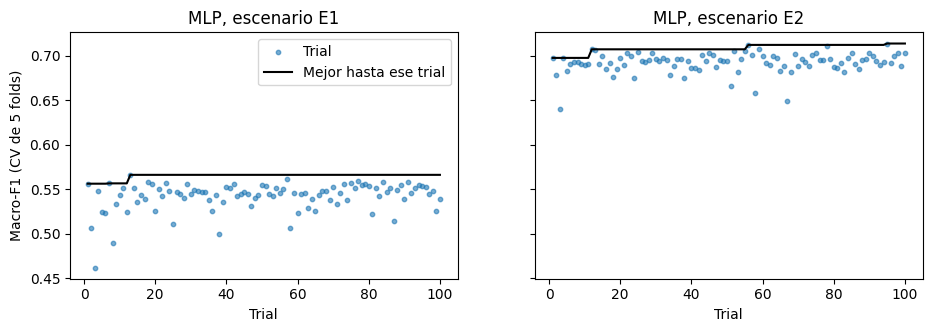

In [13]:
# Historial de Optuna del MLP: macro-F1 de cada trial y mejor valor acumulado (figura solo del notebook)
figura, ejes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for eje, escenario in zip(ejes, ESCENARIOS):
    valores = [t.value for t in ESTUDIOS[("MLP", escenario)]["estudio"].trials]
    eje.scatter(range(1, len(valores) + 1), valores, s=10, alpha=0.6, label="Trial")
    eje.plot(range(1, len(valores) + 1), np.maximum.accumulate(valores), color="black", label="Mejor hasta ese trial")
    eje.set_title(f"MLP, escenario {escenario}")
    eje.set_xlabel("Trial")
ejes[0].set_ylabel("Macro-F1 (CV de 5 folds)")
ejes[0].legend()
utilidades.guardar_figura(figura, "figura_07_optuna_historial_estudiantes")
plt.show()

**Qué observamos:** en E1, el mejor valor (0.566) aparece cerca del *trial* 13 y no mejora después; casi todos los *trials* quedan entre 0.52 y 0.56. En E2, el primer *trial* ya obtiene 0.698 y el mejor llega a 0.714. El MLP es poco sensible a sus hiperparámetros en este dataset: el límite está en la información disponible, no en la búsqueda.

## 5. GridSearchCV frente a Optuna

**Qué hacemos:** buscamos los hiperparámetros de KNN en el escenario principal (E1) con la malla completa del mismo espacio y comparamos con los 50 *trials* de Optuna.

**Por qué:** `GridSearchCV` es la herramienta del curso: prueba todas las combinaciones. La comparación mide calidad (mejor macro-F1), costo (configuraciones evaluadas) y tiempo, con los mismos folds (diseño, §8).

In [14]:
# Malla completa del espacio de KNN, incluido el balanceo (2 × 2 × 50 × 2 = 400 combinaciones)
columnas = ESCENARIOS[PRINCIPAL]
knn = crear_pipeline(KNeighborsClassifier(), PRINCIPAL, balanceo=True)
MALLA_KNN = {"modelo__n_neighbors": list(range(1, 51)), "modelo__weights": ["uniform", "distance"],
             "modelo__p": [1, 2], "balanceo": [SMOTENC(categorical_features=CATEGORICAS, random_state=SEMILLA),
                                               "passthrough"]}
inicio = time.time()
malla = GridSearchCV(knn, MALLA_KNN, cv=CV, scoring="f1_macro", n_jobs=-1).fit(train[columnas], y_train)
segundos_malla = time.time() - inicio

In [15]:
# Tabla 5: calidad, costo y tiempo de cada búsqueda (mismo espacio, mismos folds)
optuna_knn = ESTUDIOS[("KNN", PRINCIPAL)]
tabla_busqueda = pd.DataFrame([
    {"busqueda": "GridSearchCV (malla completa)", "evaluaciones": len(malla.cv_results_["params"]),
     "mejor_macro_f1_cv": malla.best_score_, "segundos": segundos_malla, "mejores_parametros": malla.best_params_},
    {"busqueda": "Optuna (TPE)", "evaluaciones": len(optuna_knn["estudio"].trials),
     "mejor_macro_f1_cv": optuna_knn["estudio"].best_value, "segundos": optuna_knn["segundos"],
     "mejores_parametros": optuna_knn["estudio"].best_params}])
tabla_busqueda.round(3)

,busqueda,evaluaciones,mejor_macro_f1_cv,segundos,mejores_parametros
0,GridSearchCV (malla completa),400,0.496,30.024,{'balanceo': SMOTENC(categorical_features=['Ma...
1,Optuna (TPE),50,0.496,10.514,"{'n_neighbors': 34, 'weights': 'distance', 'p'..."


In [16]:
# Tamaño que tendría una malla mínima del espacio del MLP (argumento de costo, no se ejecuta)
valores_por_hiperparametro = {"capas y neuronas (3 anchos por capa)": 3 + 3**2 + 3**3, "activation": 2,
                              "solver": 2, "alpha": 4, "learning_rate_init": 4, "batch_size": 4}
valores_por_hiperparametro["balanceo"] = 2
combinaciones = int(np.prod(list(valores_por_hiperparametro.values())))
segundos_por_evaluacion = ESTUDIOS[("MLP", PRINCIPAL)]["segundos"] / 100
print(f"Malla mínima del MLP: {combinaciones} combinaciones ≈ "
      f"{combinaciones * segundos_por_evaluacion / 3600:.1f} horas con el costo medio medido")

Malla mínima del MLP: 19968 combinaciones ≈ 2.1 horas con el costo medio medido


**Qué observamos:** las dos búsquedas encuentran la misma configuración de KNN y el mismo macro-F1 (0.496), pero Optuna evalúa 8 veces menos configuraciones (50 frente a 400) y tarda 10.5 s frente a 30.0 s. Una malla mínima del MLP tendría 19968 combinaciones, unas 2.2 horas con el costo medido, frente a los 100 *trials* usados.

## 6. Balanceo de clases

**Qué hacemos:** comparamos no balancear contra SMOTENC dentro de cada fold, con la mejor configuración de KNN y del MLP. En el Random Forest comparamos además SMOTENC con `class_weight="balanced"`.

**Por qué:** SMOTE (curso) interpola las columnas *one-hot* y crea categorías que no existen; SMOTENC trata las nominales como categorías. `class_weight` no existe para KNN ni MLP en scikit-learn (diseño, §5). Se usa CV 5×3 con otra semilla.

In [17]:
# KNN y MLP con sus mejores hiperparámetros, sin balanceo y con SMOTENC (escenario principal)
X, ABLACIONES = train[ESCENARIOS[PRINCIPAL]], []
for nombre in ["KNN", "MLP"]:
    parametros = ESTUDIOS[(nombre, PRINCIPAL)]["estudio"].best_params
    for balanceo in [False, True]:
        trial = optuna.trial.FixedTrial({**parametros, "balanceo": balanceo})
        puntajes = utilidades.evaluar_cv(pipeline_desde_trial(trial, nombre, PRINCIPAL), X, y_train,
                                         repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
        ABLACIONES.append({"ablacion": "balanceo", "modelo": nombre,
                           "variante": "SMOTENC" if balanceo else "sin balanceo",
                           "media": puntajes.mean(), "desviacion": puntajes.std()})
pd.DataFrame(ABLACIONES).round(3)

,ablacion,modelo,variante,media,desviacion
0,balanceo,KNN,sin balanceo,0.436,0.015
1,balanceo,KNN,SMOTENC,0.490,0.015
2,balanceo,MLP,sin balanceo,0.552,0.030
3,balanceo,MLP,SMOTENC,0.542,0.022


In [18]:
# Random Forest de referencia: SMOTENC, class_weight="balanced" o nada
variantes_rf = {"SMOTENC": (True, None), "class_weight balanced": (False, "balanced"), "sin balanceo": (False, None)}
for variante, (balanceo, pesos) in variantes_rf.items():
    rf = RandomForestClassifier(random_state=SEMILLA, class_weight=pesos, **PARAMETROS_RF[PRINCIPAL])
    puntajes = utilidades.evaluar_cv(crear_pipeline(rf, PRINCIPAL, balanceo=balanceo), X, y_train,
                                     repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
    ABLACIONES.append({"ablacion": "balanceo", "modelo": "RF (autores)", "variante": variante,
                       "media": puntajes.mean(), "desviacion": puntajes.std()})
pd.DataFrame(ABLACIONES).round(3)

,ablacion,modelo,variante,media,desviacion
0,balanceo,KNN,sin balanceo,0.436,0.015
1,balanceo,KNN,SMOTENC,0.490,0.015
2,balanceo,MLP,sin balanceo,0.552,0.030
3,balanceo,MLP,SMOTENC,0.542,0.022
4,balanceo,RF (autores),SMOTENC,0.561,0.012
5,balanceo,RF (autores),class_weight balanced,0.581,0.015
6,balanceo,RF (autores),sin balanceo,0.474,0.007


**Qué observamos:** el efecto del balanceo depende del modelo. En KNN, SMOTENC sube el macro-F1 de 0.436 a 0.490; en el MLP no ayuda (0.552 sin balanceo frente a 0.542 con SMOTENC). En el Random Forest, no balancear da 0.474, SMOTENC 0.561 y `class_weight="balanced"` 0.581: dar más peso a las clases minoritarias funciona mejor que generar filas sintéticas. La referencia de los autores se mantiene con sobremuestreo para reproducir su método (§2.2), y este resultado se discute como mejora posible.

## 7. Selección de variables

**Qué hacemos:** agregamos un selector L1 (Lasso logístico) entre el preprocesamiento y el modelo, y lo comparamos con usar todas las variables.

**Por qué:** la consigna pide selección de *features*. Lasso se vio en clase; dentro del `Pipeline` se aprende en cada fold y evita el sesgo de elegir variables mirando todos los datos (diseño, §6).

In [19]:
# Mejor configuración de KNN y MLP con selector L1 (CV 5×3, escenario principal)
for nombre in ["KNN", "MLP"]:
    trial = optuna.trial.FixedTrial(ESTUDIOS[(nombre, PRINCIPAL)]["estudio"].best_params)
    con_seleccion = pipeline_desde_trial(trial, nombre, PRINCIPAL, seleccion=True)
    puntajes = utilidades.evaluar_cv(con_seleccion, X, y_train, grupos=GRUPOS,
                                     repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
    sin_seleccion = utilidades.evaluar_cv(MODELOS_FINALES[(nombre, PRINCIPAL)], X, y_train, grupos=GRUPOS,
                                          repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
    for variante, valores in [("todas las variables", sin_seleccion), ("selector L1", puntajes)]:
        ABLACIONES.append({"ablacion": "seleccion", "modelo": nombre, "variante": variante,
                           "media": valores.mean(), "desviacion": valores.std()})
tabla_ablaciones = pd.DataFrame(ABLACIONES)
tabla_ablaciones.round(3)

,ablacion,modelo,variante,media,desviacion
0,balanceo,KNN,sin balanceo,0.436,0.015
1,balanceo,KNN,SMOTENC,0.490,0.015
2,balanceo,MLP,sin balanceo,0.552,0.030
3,balanceo,MLP,SMOTENC,0.542,0.022
4,balanceo,RF (autores),SMOTENC,0.561,0.012
5,balanceo,RF (autores),class_weight balanced,0.581,0.015
6,balanceo,RF (autores),sin balanceo,0.474,0.007
7,seleccion,KNN,todas las variables,0.490,0.015
8,seleccion,KNN,selector L1,0.492,0.013
9,seleccion,MLP,todas las variables,0.552,0.030


In [20]:
# ¿Cuántas columnas conserva el selector L1 si se ajusta con todo el train?
selector = Pipeline([("preprocesamiento", utilidades.crear_preprocesador("estudiantes", PRINCIPAL)),
                     ("seleccion", SelectFromModel(LogisticRegression(penalty="l1", solver="saga", C=1.0, max_iter=5000)))])
selector.fit(X, y_train)
conservadas = selector.named_steps["seleccion"].get_support()
nombres = selector.named_steps["preprocesamiento"].get_feature_names_out()
print("Columnas conservadas:", conservadas.sum(), "de", len(conservadas))
print("Eliminadas:", list(nombres[~conservadas]))

Columnas conservadas: 90 de 94
Eliminadas: ['nominales__Marital status_infrequent_sklearn', 'nominales__Course_infrequent_sklearn', "nominales__Father's qualification_3", 'binarias__Daytime/evening attendance']


**Qué observamos:** el selector L1 conserva 90 de las 94 columnas: elimina los grupos infrecuentes de Marital status y Course, un nivel de Father's qualification y Daytime/evening attendance. El macro-F1 casi no cambia (KNN de 0.490 a 0.492 y MLP de 0.552 a 0.546), con diferencias menores que la desviación entre *folds*. La selección no mejora los modelos, así que la configuración final usa todas las variables.

## 7.1 Sensibilidad a la regularización del selector

**Qué hacemos:** repetimos la evaluación con selector L1 de la sección 7 variando su parámetro `C` entre 0.01 y 1, con la misma configuración de KNN y del MLP, los mismos 15 *folds* y la misma semilla. En cada *fold* contamos cuántas columnas conserva el selector.

**Por qué:** en la regresión logística, `C` es el inverso de la fuerza de regularización (`C` = 1/λ, visto en clase): cuanto menor es `C`, más coeficientes lleva Lasso a cero. Con `C = 1`, fijado en el diseño antes de ver resultados, el selector casi no elimina columnas, así que la sección 7 no muestra cuánto se puede reducir. Este barrido es un análisis de sensibilidad: no cambia los modelos finales ni la comparativa. Las columnas se cuentan dentro de cada *fold* (`cross_validate` con `return_estimator=True`), nunca ajustando el selector fuera de la validación cruzada. Criterio fijado antes de ver los resultados: el rendimiento se mantiene si el macro-F1 medio queda a menos de una desviación entre *folds* del valor con `C = 1`.

In [21]:
# Barrido de C del selector L1 (CV 5×3, escenario principal): macro-F1 y columnas conservadas en cada fold
VALORES_C = [0.01, 0.05, 0.1, 0.5, 1.0]   # C = 1/λ: cuanto menor es C, más fuerte la penalización L1
FOLDS_COMPARATIVA = [particion for repeticion in range(3)   # los mismos 15 folds que usa evaluar_cv
                     for particion in StratifiedKFold(n_splits=5, shuffle=True,
                                                      random_state=utilidades.SEMILLA_COMPARATIVA + repeticion).split(X, y_train)]
BARRIDO_C = []
for nombre in ["KNN", "MLP"]:
    trial = optuna.trial.FixedTrial(ESTUDIOS[(nombre, PRINCIPAL)]["estudio"].best_params)
    for c in VALORES_C:
        pipeline = pipeline_desde_trial(trial, nombre, PRINCIPAL, seleccion=True).set_params(seleccion__estimator__C=c)
        cv = cross_validate(pipeline, X, y_train, cv=FOLDS_COMPARATIVA, scoring="f1_macro", return_estimator=True, n_jobs=-1)
        soportes = [modelo.named_steps["seleccion"].get_support() for modelo in cv["estimator"]]   # columnas elegidas en cada fold
        BARRIDO_C.append({"modelo": nombre, "C": c, "media": cv["test_score"].mean(), "desviacion": cv["test_score"].std(),
                          "columnas_media": np.mean([s.sum() for s in soportes]), "columnas_total": np.mean([s.size for s in soportes]),
                          "columnas_min": min(s.sum() for s in soportes), "columnas_max": max(s.sum() for s in soportes)})

In [22]:
# Tabla 8 y control de coherencia: con C = 1 debe repetirse la fila "selector L1" de la sección 7
tabla_seleccion_c = pd.DataFrame(BARRIDO_C)
seccion_7 = tabla_ablaciones.query("ablacion == 'seleccion' and variante == 'selector L1'").set_index("modelo")["media"]
for nombre in ["KNN", "MLP"]:
    con_c1 = tabla_seleccion_c.query("modelo == @nombre and C == 1.0")["media"].item()
    print(f"{nombre}: C = 1 da {con_c1:.4f}; la sección 7 da {seccion_7[nombre]:.4f} (diferencia {con_c1 - seccion_7[nombre]:+.4f})")
tabla_seleccion_c.round(3)

KNN: C = 1 da 0.4924; la sección 7 da 0.4924 (diferencia +0.0000)
MLP: C = 1 da 0.5459; la sección 7 da 0.5459 (diferencia +0.0000)


,modelo,C,media,desviacion,columnas_media,columnas_total,columnas_min,columnas_max
0,KNN,0.01,0.500,0.011,7.533,91.867,6,10
1,KNN,0.05,0.508,0.019,43.000,91.867,39,48
2,KNN,0.10,0.498,0.013,65.933,91.867,60,70
3,KNN,0.50,0.493,0.014,85.667,91.867,82,89
4,KNN,1.00,0.492,0.013,88.467,91.867,85,92
5,MLP,0.01,0.441,0.011,6.200,94.867,5,7
6,MLP,0.05,0.514,0.026,20.200,94.867,18,23
7,MLP,0.10,0.544,0.015,41.667,94.867,38,48
8,MLP,0.50,0.549,0.022,83.200,94.867,78,89
9,MLP,1.00,0.546,0.029,88.133,94.867,84,93


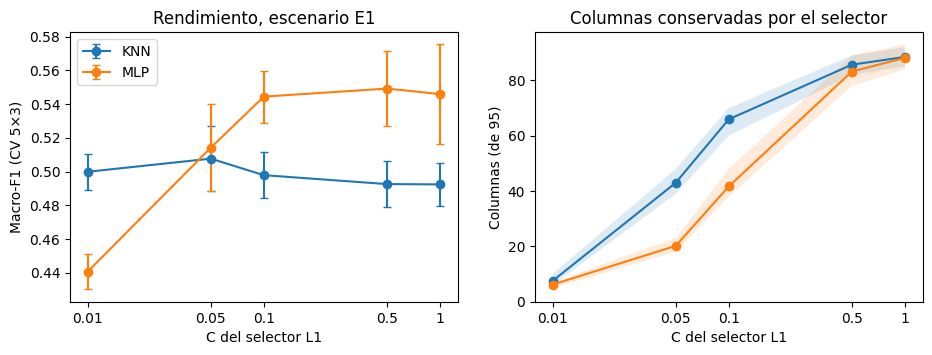

In [23]:
# Figura 8: macro-F1 (media ± desviación) y columnas conservadas (media y rango de los 15 folds) según C
figura, (eje_f1, eje_columnas) = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for nombre, filas in tabla_seleccion_c.groupby("modelo"):
    eje_f1.errorbar(filas["C"], filas["media"], yerr=filas["desviacion"], marker="o", capsize=3, label=nombre)
    eje_columnas.plot(filas["C"], filas["columnas_media"], marker="o", label=nombre)
    eje_columnas.fill_between(filas["C"], filas["columnas_min"], filas["columnas_max"], alpha=0.15)
eje_f1.set_xscale("log")   # los valores de C quedan equiespaciados
eje_f1.set_xticks(VALORES_C, [f"{c:g}" for c in VALORES_C])
eje_f1.xaxis.set_minor_locator(plt.NullLocator())
eje_f1.set(xlabel="C del selector L1", ylabel="Macro-F1 (CV 5×3)", title=f"Rendimiento, escenario {PRINCIPAL}")
eje_columnas.set(xlabel="C del selector L1", ylabel=f"Columnas (de {tabla_seleccion_c['columnas_total'].max():.0f})",
                 title="Columnas conservadas por el selector", ylim=(0, None))
eje_f1.legend()
utilidades.guardar_figura(figura, "figura_08_seleccion_c_estudiantes")
plt.show()

**Qué observamos:** <!-- obs:seleccion_C --> con `C = 1` se repite exactamente la fila "selector L1" de la sección 7 (0.492 en KNN y 0.546 en el MLP), lo que confirma que el barrido usa los mismos *folds*. Al bajar `C`, Lasso elimina muchas más columnas: en el MLP pasa de unas 88 por *fold* con `C = 1` a 42 con `C = 0.1`, 20 con `C = 0.05` y 6 con `C = 0.01`; en KNN, de 88 a 66, 43 y 8. Con el criterio fijado antes de ver los resultados (menos de una desviación entre *folds* respecto de `C = 1`), el MLP mantiene su rendimiento hasta `C = 0.1` (0.544 frente a 0.546) con 42 de 95 columnas, y lo pierde con valores menores (0.514 con 20 columnas y 0.441 con 6). KNN no pierde rendimiento en todo el rango: con `C = 0.01` conserva entre 6 y 10 columnas y obtiene 0.500, y con `C = 0.05` llega a 0.508, algo más de una desviación por encima de 0.492. Una explicación posible es que las distancias de KNN se vuelven menos informativas cuando hay muchas columnas que aportan poco. En conclusión, la selección L1 puede dejar menos de la mitad de las columnas sin pérdida, pero no mejora al mejor modelo nuevo (el MLP). La configuración final se mantiene con `C = 1`, como se fijó en el diseño, y este resultado se reporta como análisis de sensibilidad. KNN parte de unas 92 columnas, y no de 95, porque SMOTENC se aplica antes de la codificación y cambia qué niveles superan el 1%.

## 8. Comparativa por validación cruzada

**Qué hacemos:** evaluamos todas las configuraciones finales con CV de 5 folds repetida 3 veces y otra semilla.

**Por qué:** la comparativa reporta media ± desviación de 15 valores por modelo (diseño, §10). Usar otra semilla que en la búsqueda reduce el optimismo de evaluar con los mismos folds que eligieron los hiperparámetros. Regla fijada de antemano: la configuración final de cada modelo es la mejor de su búsqueda; las ablaciones de las secciones 6 y 7 se reportan, pero no la cambian.

In [24]:
# CV 5×3 de cada configuración final (puede tardar unos minutos)
PUNTAJES, COMPARATIVA = {}, []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for (nombre, escenario), pipeline in MODELOS_FINALES.items():
        valores = utilidades.evaluar_cv(pipeline, train[ESCENARIOS[escenario]], y_train, grupos=GRUPOS,
                                        repeticiones=3, semilla=utilidades.SEMILLA_COMPARATIVA)
        PUNTAJES[(nombre, escenario)] = valores
        COMPARATIVA.append({"modelo": nombre, "escenario": escenario, "media": valores.mean(),
                            "desviacion": valores.std(), "minimo": valores.min(), "maximo": valores.max()})
tabla_comparativa = pd.DataFrame(COMPARATIVA).sort_values(["escenario", "media"], ascending=[True, False])
tabla_comparativa.round(3)

,modelo,escenario,media,desviacion,minimo,maximo
2,RF (autores),E1,0.561,0.012,0.546,0.585
5,MLP,E1,0.552,0.030,0.467,0.594
4,KNN,E1,0.490,0.015,0.462,0.515
0,Dummy,E1,0.222,0.000,0.222,0.222
3,RF (autores),E2,0.716,0.015,0.692,0.747
7,MLP,E2,0.692,0.024,0.655,0.737
6,KNN,E2,0.638,0.011,0.622,0.657
1,Dummy,E2,0.222,0.000,0.222,0.222


In [25]:
# Wilcoxon (escenario principal): mejor método nuevo frente a la referencia de los autores
nuevos = tabla_comparativa[(tabla_comparativa["escenario"] == PRINCIPAL) & tabla_comparativa["modelo"].isin(["KNN", "MLP"])]
MEJOR = nuevos.sort_values("media", ascending=False)["modelo"].iloc[0]
referencia = "RF (autores)"
estadistico, p_valor = wilcoxon(PUNTAJES[(MEJOR, PRINCIPAL)], PUNTAJES[(referencia, PRINCIPAL)])
diferencia = PUNTAJES[(MEJOR, PRINCIPAL)].mean() - PUNTAJES[(referencia, PRINCIPAL)].mean()
print(f"Mejor método nuevo en {PRINCIPAL}: {MEJOR}. Diferencia de macro-F1 frente a {referencia}: {diferencia:+.3f}")
print(f"Wilcoxon sobre 15 folds pareados: estadístico = {estadistico:.1f}, p = {p_valor:.4f}")
print("Los folds de una CV repetida no son independientes: el valor p es orientativo (diseño, §10).")

Mejor método nuevo en E1: MLP. Diferencia de macro-F1 frente a RF (autores): -0.009
Wilcoxon sobre 15 folds pareados: estadístico = 41.0, p = 0.3028
Los folds de una CV repetida no son independientes: el valor p es orientativo (diseño, §10).


**Qué observamos:** en E1, el escenario principal, el Random Forest de los autores obtiene 0.561 ± 0.012, el MLP 0.552 ± 0.030 y KNN 0.490 ± 0.015; el Dummy queda en 0.222. En E2, el orden se mantiene: RF 0.716, MLP 0.692 y KNN 0.638. La diferencia entre el MLP y el RF en E1 (−0.009) no es significativa (Wilcoxon *p* = 0.30). Los métodos nuevos no superan al método de los autores: el MLP queda a la par y KNN claramente por debajo, porque las distancias en 94 columnas, casi todas binarias, separan mal a los estudiantes.

## 9. Evaluación final en el test

**Qué hacemos:** reentrenamos cada configuración final con todo el train y la evaluamos una sola vez en el test.

**Por qué:** el test de reserva da la estimación sin sesgo del desempeño; después de verlo no se cambia ninguna decisión (diseño, §7.5).

In [26]:
# Entrenar con todo el train y medir en el test (tabla 4)
MODELOS_ENTRENADOS, METRICAS_TEST = {}, []
for (nombre, escenario), pipeline in MODELOS_FINALES.items():
    columnas = ESCENARIOS[escenario]
    modelo = clone(pipeline).fit(train[columnas], y_train)
    MODELOS_ENTRENADOS[(nombre, escenario)] = modelo
    METRICAS_TEST.append({"modelo": nombre, "escenario": escenario,
                          **utilidades.metricas_test(modelo, test[columnas], y_test, "estudiantes")})
tabla_test = pd.DataFrame(METRICAS_TEST)
tabla_test.round(3)

,modelo,escenario,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
0,Dummy,E1,0.499,0.333,0.166,0.333,0.222,0.500
1,Dummy,E2,0.499,0.333,0.166,0.333,0.222,0.500
2,RF (autores),E1,0.576,0.563,0.555,0.563,0.549,0.763
3,RF (autores),E2,0.749,0.698,0.701,0.698,0.698,0.883
4,KNN,E1,0.494,0.497,0.505,0.497,0.476,0.678
5,MLP,E1,0.631,0.528,0.552,0.528,0.529,0.759
6,KNN,E2,0.656,0.622,0.645,0.622,0.615,0.832
7,MLP,E2,0.767,0.683,0.707,0.683,0.689,0.881


In [27]:
# Convergencia del MLP final: iteraciones usadas frente al máximo permitido
for escenario in ESCENARIOS:
    mlp = MODELOS_ENTRENADOS[("MLP", escenario)].named_steps["modelo"]
    print(f"MLP {escenario}: {mlp.n_iter_} iteraciones de {mlp.max_iter} (early stopping)")

MLP E1: 16 iteraciones de 500 (early stopping)
MLP E2: 19 iteraciones de 500 (early stopping)


In [28]:
# F1 de cada clase en el test (escenario principal)
from sklearn.metrics import f1_score
f1_por_clase = {nombre: f1_score(y_test, MODELOS_ENTRENADOS[(nombre, PRINCIPAL)].predict(test[ESCENARIOS[PRINCIPAL]]),
                                 average=None)
                for nombre in [m for m, e in MODELOS_ENTRENADOS if e == PRINCIPAL]}
pd.DataFrame(f1_por_clase, index=CLASES).round(3)

,Dummy,RF (autores),KNN,MLP
Dropout,0.000,0.628,0.486,0.626
Enrolled,0.000,0.373,0.353,0.227
Graduate,0.666,0.645,0.588,0.733


**Qué observamos:** en el test, E1 da un macro-F1 de 0.549 para el RF, 0.529 para el MLP y 0.476 para KNN (Dummy 0.222); en E2, 0.698, 0.689 y 0.615. El MLP tiene el mayor *accuracy* en E1 (0.631), pero menor macro-F1 que el RF: acierta mucho Graduate (F1 0.733) y casi nunca Enrolled (0.227), mientras que el RF reconoce mejor Enrolled (0.373). Es la consecuencia de que el MLP se entrenara sin balanceo, y muestra por qué el *accuracy* no basta con clases desbalanceadas. El MLP converge por *early stopping* en 16 y 19 iteraciones.

## 10. Interpretación del mejor modelo

**Qué hacemos:** analizamos el mejor método nuevo del escenario principal con su matriz de confusión, la importancia por permutación de cada variable y la curva de aprendizaje.

**Por qué:** explican qué aprendió el modelo, en qué clases se equivoca y si sufre de sesgo o de varianza (diseño, §10). Hay que revisar el peso de las variables macroeconómicas (cohorte) y de Debtor y Tuition fees (momento de medición desconocido).

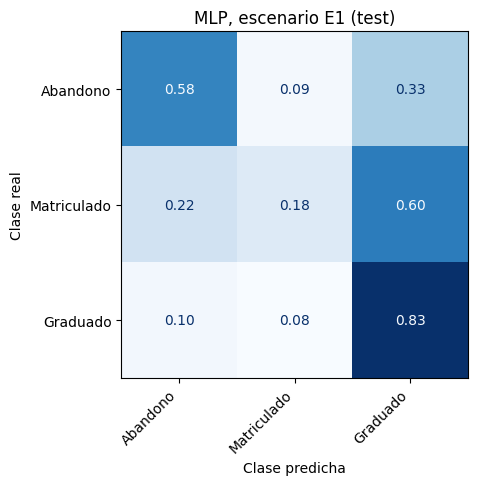

In [29]:
# Figura 4: matriz de confusión del mejor modelo en el test (proporciones por clase real)
from sklearn.metrics import ConfusionMatrixDisplay
modelo_mejor = MODELOS_ENTRENADOS[(MEJOR, PRINCIPAL)]
X_test = test[ESCENARIOS[PRINCIPAL]]
figura, eje = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_estimator(modelo_mejor, X_test, y_test, display_labels=ETIQUETAS, normalize="true",
                                      values_format=".2f", cmap="Blues", ax=eje, colorbar=False)
eje.set_title(f"{MEJOR}, escenario {PRINCIPAL} (test)")
eje.set_xlabel("Clase predicha")
eje.set_ylabel("Clase real")
plt.xticks(rotation=45, ha="right")
utilidades.guardar_figura(figura, "figura_04_confusion_estudiantes")
plt.show()

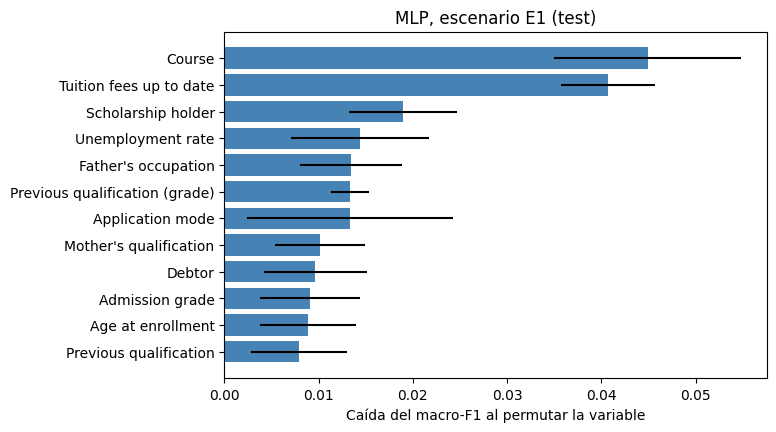

,media,desviacion
Course,0.045,0.010
Tuition fees up to date,0.041,0.005
Scholarship holder,0.019,0.006
Unemployment rate,0.014,0.007
Father's occupation,0.013,0.005
Previous qualification (grade),0.013,0.002
Application mode,0.013,0.011
Mother's qualification,0.010,0.005
Debtor,0.010,0.005
Admission grade,0.009,0.005


In [30]:
# Figura 5: importancia por permutación en el test (caída del macro-F1 al desordenar cada variable)
from sklearn.inspection import permutation_importance
importancia = permutation_importance(modelo_mejor, X_test, y_test, scoring="f1_macro",
                                     n_repeats=10, random_state=SEMILLA, n_jobs=-1)
tabla_importancia = pd.DataFrame({"media": importancia.importances_mean, "desviacion": importancia.importances_std},
                                 index=X_test.columns).sort_values("media", ascending=False)
figura, eje = plt.subplots(figsize=(7, 4.5))
principales = tabla_importancia.head(12).iloc[::-1]
eje.barh(principales.index, principales["media"], xerr=principales["desviacion"], color="steelblue")
eje.set_xlabel("Caída del macro-F1 al permutar la variable")
eje.set_title(f"{MEJOR}, escenario {PRINCIPAL} (test)")
utilidades.guardar_figura(figura, "figura_05_importancia_estudiantes")
plt.show()
tabla_importancia.head(12).round(3)

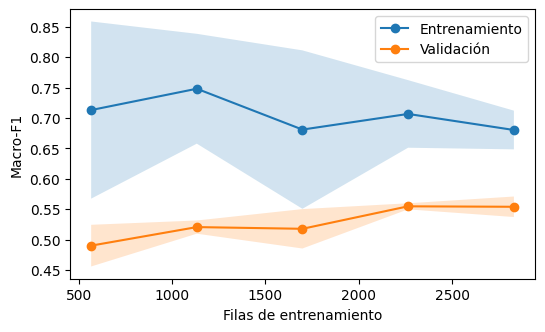

In [31]:
# Figura 6: curva de aprendizaje del mejor modelo (CV de 5 folds sobre el train)
from sklearn.model_selection import learning_curve
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    tamanos, puntaje_train, puntaje_validacion = learning_curve(
        MODELOS_FINALES[(MEJOR, PRINCIPAL)], train[ESCENARIOS[PRINCIPAL]], y_train, cv=CV,
        scoring="f1_macro", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1,
        shuffle=True, random_state=SEMILLA)   # barajar: el CSV de obesidad viene ordenado por clase
figura, eje = plt.subplots(figsize=(6, 3.5))
for valores, etiqueta in [(puntaje_train, "Entrenamiento"), (puntaje_validacion, "Validación")]:
    eje.plot(tamanos, valores.mean(axis=1), marker="o", label=etiqueta)
    eje.fill_between(tamanos, valores.mean(axis=1) - valores.std(axis=1), valores.mean(axis=1) + valores.std(axis=1), alpha=0.2)
eje.set_xlabel("Filas de entrenamiento")
eje.set_ylabel("Macro-F1")
eje.legend()
utilidades.guardar_figura(figura, "figura_06_curva_aprendizaje_estudiantes")
plt.show()

**Qué observamos:** en la matriz de confusión del MLP en E1, el 83% de los Graduados se reconocen bien, pero un tercio de los Abandonos se predicen como Graduados y solo el 18% de los Matriculados se reconoce (el 60% se confunde con Graduado). Al momento de matricularse, quien terminará matriculado es casi indistinguible de quien se graduará. La importancia por permutación coloca primero a Course (0.045) y a Tuition fees up to date (0.041), seguidas de Scholarship holder (0.019) y Unemployment rate (0.014). Dos alertas para la Discusión: Tuition fees es la segunda variable más importante y no se sabe si se registró al matricularse, y Unemployment rate funciona como indicador de cohorte. La curva de aprendizaje muestra una brecha moderada (0.68 en entrenamiento frente a 0.555 en validación) y una validación que se estanca desde unas 2300 filas: más filas del mismo tipo ayudarían poco. El límite es la información disponible al matricularse, es decir, un problema de sesgo más que de varianza.

## 11. Registro de resultados

**Qué hacemos:** guardamos las tablas del reporte y el registro largo de resultados de este notebook.

**Por qué:** el reporte toma sus cifras solo de `resultados/` (diseño, §11.2).

In [32]:
# Registro largo: comparativa y ablaciones (CV) y métricas del test
for fila in COMPARATIVA:
    configuracion = MODELOS_FINALES[(fila["modelo"], fila["escenario"])].named_steps["modelo"].get_params()
    utilidades.registrar_resultado(filas_resultados, "estudiantes", fila["escenario"], fila["modelo"], configuracion,
                                   "f1_macro", fila["media"], fila["desviacion"], "CV")
for fila in ABLACIONES:
    utilidades.registrar_resultado(filas_resultados, "estudiantes", PRINCIPAL, fila["modelo"], fila["ablacion"] + ": " + fila["variante"],
                                   "f1_macro", fila["media"], fila["desviacion"], "CV")
for fila in METRICAS_TEST:
    for metrica, valor in fila.items():
        if metrica not in ["modelo", "escenario"]:
            utilidades.registrar_resultado(filas_resultados, "estudiantes", fila["escenario"], fila["modelo"], "final",
                                           metrica, valor, None, "test")
print("Filas registradas:", len(filas_resultados))

Filas registradas: 67


In [33]:
# Registro del barrido de C (sección 7.1): macro-F1 y columnas conservadas por valor de C
for fila in BARRIDO_C:
    configuracion = f"seleccion L1: C={fila['C']:g}"
    utilidades.registrar_resultado(filas_resultados, "estudiantes", PRINCIPAL, fila["modelo"], configuracion,
                                   "f1_macro", fila["media"], fila["desviacion"], "CV")
    utilidades.registrar_resultado(filas_resultados, "estudiantes", PRINCIPAL, fila["modelo"], configuracion,
                                   "columnas_conservadas", fila["columnas_media"], None, "CV")
print("Filas registradas:", len(filas_resultados))

Filas registradas: 87


In [34]:
# Guardar las tablas del reporte y el registro
utilidades.guardar_tabla(tabla_hiperparametros, "tabla_02_hiperparametros_estudiantes")
utilidades.guardar_tabla(tabla_comparativa, "tabla_03_comparativa_cv_estudiantes")
utilidades.guardar_tabla(tabla_test, "tabla_04_metricas_test_estudiantes")
utilidades.guardar_tabla(tabla_busqueda, "tabla_05_grid_vs_optuna_estudiantes")
utilidades.guardar_tabla(tabla_ablaciones, "tabla_06_ablaciones_estudiantes")
utilidades.guardar_tabla(tabla_seleccion_c, "tabla_08_seleccion_c_estudiantes")
utilidades.guardar_tabla(pd.DataFrame(filas_resultados), "resultados_estudiantes")
print("Tablas guardadas en resultados/tablas/")

Tablas guardadas en resultados/tablas/


## Guardar resultados en GitHub (solo corrida oficial en Colab)

**Qué hacemos:** subimos a `main` los archivos de `resultados/` que genera este notebook.

**Por qué:** las cifras del reporte deben salir de la misma corrida que deja las salidas visibles en el notebook (§12, regla 4). En VS Code esta celda no hace nada; Marcelo hace el *commit* desde VS Code. Después de esta celda, guardar el notebook con *File → Save a copy in GitHub*.

In [35]:
# Celda final. Cambiar a True solo en la corrida oficial, después de "Reiniciar y ejecutar todo".
import glob

GUARDAR_EN_GITHUB = False
PATRONES_DE_ESTE_NOTEBOOK = ["resultados/tablas/tabla_0[2-8]_*estudiantes.csv", "resultados/tablas/resultados_estudiantes.csv", "resultados/figuras/figura_0[4-8]_*estudiantes.png"]
if EN_COLAB and GUARDAR_EN_GITHUB:
    archivos = " ".join(f for patron in PATRONES_DE_ESTE_NOTEBOOK for f in sorted(glob.glob(patron)))
    nombre, correo = userdata.get("GITHUB_NOMBRE"), userdata.get("GITHUB_CORREO")
    !git config user.name "{nombre}"
    !git config user.email "{correo}"
    !git add {archivos}
    !git commit -q -m "02-estudiantes: actualiza resultados de la corrida oficial"
    !git pull -q --rebase
    !git push -q
    print("Archivos subidos:", archivos)